# Assignment 3 — Probability and KDE

This notebook answers the probability questions about two coins and estimates a kernel density from the frequency table. The code includes checks for the probability formulas and the KDE calculation.

## 1. Probability model

Suzanne scores 2 on heads (probability `p`) and 3 on tails. Jim scores 1 on heads (probability `q`) and 2 on tails. Their flips are independent. The possible sums are:

| Sum | Outcomes | Probability |
|---:|---|---|
| 3 | A heads, B heads | `p q` |
| 4 | A heads/B tails, or A tails/B heads | `p(1-q) + (1-p)q` |
| 5 | A tails, B tails | `(1-p)(1-q)` |

The probabilities add to 1. For observations `X`, the log-likelihood is the sum of the log-probability of each observed sum. If the counts of sums 3, 4, and 5 are `n3`, `n4`, and `n5`, respectively, then `log L = n3 log(P3) + n4 log(P4) + n5 log(P5)`. The multinomial coefficient is omitted because it does not depend on `p` or `q` and therefore does not change the maximum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def _validate_probabilities(p, q):
    if not (np.isscalar(p) and np.isscalar(q)):
        raise ValueError("p and q must be scalar probabilities.")
    if not (np.isfinite(p) and np.isfinite(q) and 0 <= p <= 1 and 0 <= q <= 1):
        raise ValueError("p and q must be between 0 and 1, inclusive.")

def probability_sum(p, q, v):
    """Return P(sum of scores = v) for v in {3, 4, 5}."""
    _validate_probabilities(p, q)
    probabilities = {
        3: p * q,
        4: p * (1 - q) + (1 - p) * q,
        5: (1 - p) * (1 - q),
    }
    if v not in probabilities:
        raise ValueError("v must be one of 3, 4, or 5.")
    return float(probabilities[v])

def log_likelihood_from_counts(p, q, counts):
    """Return log-likelihood from counts ordered as [n3, n4, n5]."""
    _validate_probabilities(p, q)
    counts = np.asarray(counts)
    if counts.shape != (3,) or np.any(counts < 0):
        raise ValueError("counts must contain three nonnegative values [n3, n4, n5].")
    probabilities = np.array([
        probability_sum(p, q, 3),
        probability_sum(p, q, 4),
        probability_sum(p, q, 5),
    ])
    positive_counts = counts > 0
    if np.any((probabilities == 0) & positive_counts):
        return -np.inf
    return float(np.sum(counts[positive_counts] * np.log(probabilities[positive_counts])))

def log_likelihood(p, q, X):
    """Return the log-likelihood of a list/array of observed sums X."""
    _validate_probabilities(p, q)
    observations = np.asarray(X)
    if observations.ndim != 1 or not np.all(np.isin(observations, [3, 4, 5])):
        raise ValueError("X must be a one-dimensional list or array containing only 3, 4, and 5.")
    counts = np.array([np.count_nonzero(observations == v) for v in (3, 4, 5)])
    return log_likelihood_from_counts(p, q, counts)

# Basic checks: probabilities normalize, the functions match direct calculations,
# and invalid inputs are rejected.
assert np.isclose(sum(probability_sum(0.37, 0.62, v) for v in (3, 4, 5)), 1.0)
assert np.isclose(probability_sum(0.5, 0.4, 3), 0.20)
assert np.isclose(probability_sum(0.5, 0.4, 4), 0.50)
assert np.isclose(probability_sum(0.5, 0.4, 5), 0.30)
assert np.isclose(log_likelihood(0.5, 0.4, [3, 4, 5]), np.log(0.20) + np.log(0.50) + np.log(0.30))
try:
    probability_sum(1.2, 0.5, 3)
except ValueError:
    pass
else:
    raise AssertionError("Out-of-range coin probabilities should raise ValueError.")
try:
    log_likelihood(0.5, 0.5, [2])
except ValueError:
    pass
else:
    raise AssertionError("Unsupported sums should raise ValueError.")
print("Probability and log-likelihood checks passed.")

Matplotlib is building the font cache; this may take a moment.


Probability and log-likelihood checks passed.


### Observed experiment results

The provided experiment has 148 sums of 3, 529 sums of 4, and 323 sums of 5. This cell makes the requested observation list and evaluates its log-likelihood for one example parameter pair.

In [2]:
observed_counts = np.array([148, 529, 323])
observations = np.repeat(np.array([3, 4, 5]), observed_counts)
assert len(observations) == 1000

example_p, example_q = 0.5, 0.5
print(f"Observation count: {len(observations)}")
print(f"Log-likelihood at p=q=0.5: {log_likelihood(example_p, example_q, observations):.6f}")
assert np.isclose(
    log_likelihood(example_p, example_q, observations),
    log_likelihood_from_counts(example_p, example_q, observed_counts),
)

Observation count: 1000
Log-likelihood at p=q=0.5: -1019.619503


### (c) Likelihood over `p` and `q`

The following contour plot evaluates the log-likelihood on a grid over the requested interval `(0, 1)`. The red stars mark the two analytic maximum-likelihood parameter pairs.

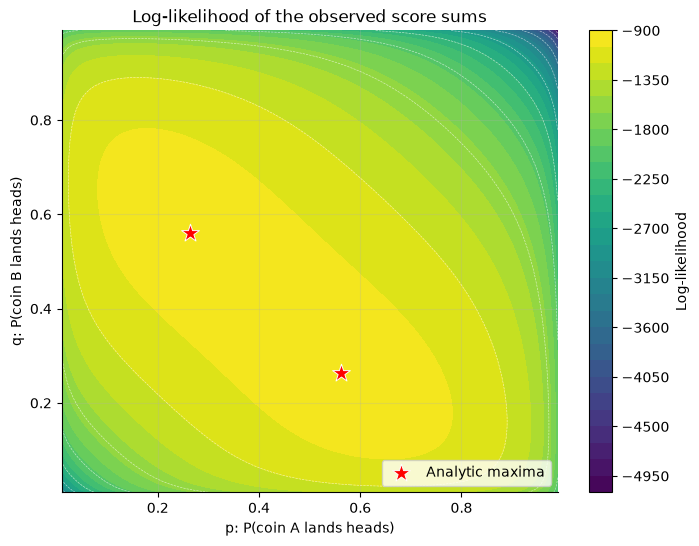

Observed proportions (sums 3, 4, 5): 0.148, 0.529, 0.323
Maximum log-likelihood: -984.633282
Maximum parameter pairs: (0.263650, 0.561350) and (0.561350, 0.263650)


In [3]:
sample_size = observed_counts.sum()
frequency_3, frequency_4, frequency_5 = observed_counts / sample_size

# At the maximum, the model probabilities match the observed proportions.
# pq = f3 and (1-p)(1-q) = f5 imply p+q = 1 + f3 - f5.
sum_pq = 1 + frequency_3 - frequency_5
discriminant = sum_pq**2 - 4 * frequency_3
assert discriminant >= 0
p_hat_low = (sum_pq - np.sqrt(discriminant)) / 2
p_hat_high = (sum_pq + np.sqrt(discriminant)) / 2

# The likelihood is unchanged when p and q are swapped.
mle_pairs = [(p_hat_low, p_hat_high), (p_hat_high, p_hat_low)]
max_log_likelihood = log_likelihood_from_counts(p_hat_low, p_hat_high, observed_counts)

p_grid = np.linspace(0.01, 0.99, 240)
q_grid = np.linspace(0.01, 0.99, 240)
P, Q = np.meshgrid(p_grid, q_grid)
P3 = P * Q
P4 = P * (1 - Q) + (1 - P) * Q
P5 = (1 - P) * (1 - Q)
log_likelihood_grid = (
    observed_counts[0] * np.log(P3)
    + observed_counts[1] * np.log(P4)
    + observed_counts[2] * np.log(P5)
)

fig, ax = plt.subplots(figsize=(8, 6))
filled = ax.contourf(P, Q, log_likelihood_grid, levels=32, cmap="viridis")
ax.contour(P, Q, log_likelihood_grid, levels=12, colors="white", linewidths=0.45, alpha=0.65)
ax.scatter(
    [pair[0] for pair in mle_pairs],
    [pair[1] for pair in mle_pairs],
    color="red", marker="*", s=180, edgecolor="white", linewidth=0.7,
    label="Analytic maxima", zorder=3,
)
ax.set(xlabel="p: P(coin A lands heads)", ylabel="q: P(coin B lands heads)",
       title="Log-likelihood of the observed score sums")
ax.legend(loc="lower right")
fig.colorbar(filled, ax=ax, label="Log-likelihood")
plt.show()

print(f"Observed proportions (sums 3, 4, 5): {frequency_3:.3f}, {frequency_4:.3f}, {frequency_5:.3f}")
print(f"Maximum log-likelihood: {max_log_likelihood:.6f}")
print(f"Maximum parameter pairs: ({p_hat_low:.6f}, {p_hat_high:.6f}) and ({p_hat_high:.6f}, {p_hat_low:.6f})")
assert np.isclose(probability_sum(p_hat_low, p_hat_high, 3), frequency_3)
assert np.isclose(probability_sum(p_hat_low, p_hat_high, 4), frequency_4)
assert np.isclose(probability_sum(p_hat_low, p_hat_high, 5), frequency_5)
assert np.isclose(max_log_likelihood, log_likelihood_from_counts(p_hat_high, p_hat_low, observed_counts))

### (d) Number of maxima and consequence

There are **two global maxima**, related by swapping `p` and `q`. The likelihood depends on the score-sum probabilities, which are unchanged by this swap. Both parameter pairs reproduce the observed proportions exactly, so the data identify the two estimated probabilities as an unordered pair but cannot determine which estimate belongs to coin A versus coin B.

### (e) Estimates

The estimates are approximately `0.26365` and `0.56135`. Thus either `(p, q) = (0.26365, 0.56135)` or `(p, q) = (0.56135, 0.26365)` maximizes the likelihood. More information than the sums (for example, recording the two individual scores) would be needed to assign the two estimates to the named coins.

## 2. KDE for the frequency table

Each listed value is treated as an observation repeated according to its occurrence count, giving `1500` observations in total. I use a Gaussian kernel and Silverman's rule-of-thumb bandwidth, `h = 0.9 min(s, IQR/1.34) n^(-1/5)`. This gives a reproducible starting bandwidth based on the sample scale and size. The table is concentrated on separated values, so the plot also compares half and twice this bandwidth: a smaller bandwidth can make the curve overly spiky, while a larger one can merge distinct groups. The selected bandwidth is the rule-of-thumb value, with those neighboring curves shown as a sensitivity check.

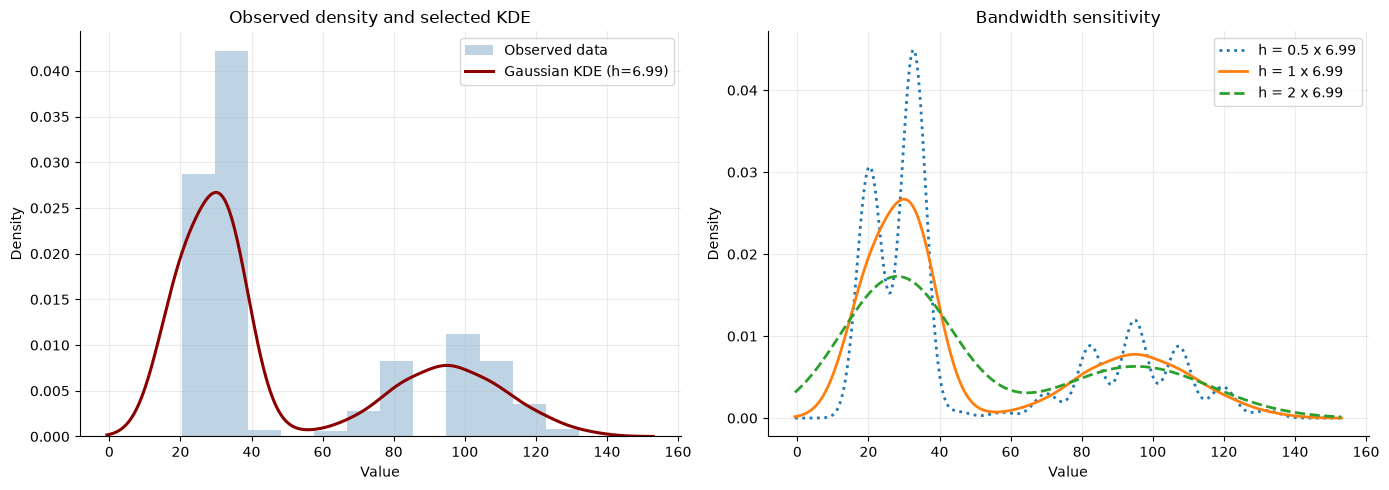

Expanded observation count: 1500
Silverman bandwidth: 6.9933
Approximate KDE area on plotted grid: 0.9996
KDE checks passed.


In [4]:
values = np.array([20.3, 32.7, 45.2, 57.6, 70.0, 82.4, 94.9, 107.3, 119.7, 132.1])
frequencies = np.array([402, 590, 10, 9, 39, 116, 157, 115, 50, 12])
sample = np.repeat(values, frequencies)
n = sample.size

standard_deviation = np.std(sample, ddof=1)
q1, q3 = np.percentile(sample, [25, 75])
robust_scale = (q3 - q1) / 1.34
scale = min(standard_deviation, robust_scale)
bandwidth = 0.9 * scale * n ** (-1 / 5)

def weighted_gaussian_kde(grid, support_values, weights, h):
    """Evaluate a Gaussian KDE from unique values and their frequencies."""
    if h <= 0:
        raise ValueError("Bandwidth must be positive.")
    standardized = (grid[:, None] - support_values[None, :]) / h
    kernels = np.exp(-0.5 * standardized**2)
    return kernels @ weights / (weights.sum() * h * np.sqrt(2 * pi))

grid = np.linspace(sample.min() - 3 * bandwidth, sample.max() + 3 * bandwidth, 1200)
density = weighted_gaussian_kde(grid, values, frequencies, bandwidth)

assert n == 1500
assert np.all(np.isfinite(density)) and np.all(density >= 0)
approximate_area = density.sum() * (grid[1] - grid[0])
assert 0.99 < approximate_area < 1.01

fig, (ax, sensitivity_ax) = plt.subplots(1, 2, figsize=(14, 5))
ax.hist(sample, bins="auto", density=True, alpha=0.35, color="steelblue", label="Observed data")
ax.plot(grid, density, color="darkred", linewidth=2.2, label=f"Gaussian KDE (h={bandwidth:.2f})")
ax.set(xlabel="Value", ylabel="Density", title="Observed density and selected KDE")
ax.legend()

for multiplier, style in [(0.5, ":"), (1.0, "-"), (2.0, "--")]:
    sensitivity_density = weighted_gaussian_kde(grid, values, frequencies, bandwidth * multiplier)
    sensitivity_ax.plot(
        grid, sensitivity_density, linestyle=style, linewidth=2,
        label=f"h = {multiplier:g} x {bandwidth:.2f}",
    )
sensitivity_ax.set(xlabel="Value", ylabel="Density", title="Bandwidth sensitivity")
sensitivity_ax.legend()
fig.tight_layout()
plt.show()

print(f"Expanded observation count: {n}")
print(f"Silverman bandwidth: {bandwidth:.4f}")
print(f"Approximate KDE area on plotted grid: {approximate_area:.4f}")
print("KDE checks passed.")